# Lab 11: Probing Pre-trained BERT Encoder Layers for Linguistic Properties

### **Assignment Objective & Specifications:**
1. **Data Source:** Fetch data from [SentEval Probing Tasks](https://github.com/facebookresearch/SentEval/tree/main/data/probing).
2. **Three Probing Tasks:**
   - **Sentence Length (`sentence_length.txt` / SentLen):** Surface-level linguistic property (predicting the length category of a sentence into 6 bins).
   - **Bigram Shift (`bigram_shift.txt` / BShift):** Syntactic property / word order sensitivity (binary classification: whether two adjacent words have been inverted `I` or original `O`).
   - **Subject Number (`subj_number.txt` / SubjNum):** Syntactic agreement property (binary classification: whether the subject of the main clause is singular `NN` or plural `NNS`).
3. **Dataset Sampling & Balancing:**
   - Sample exactly **50,000 samples** from each dataset.
   - Perfectly balance the class distribution across all target classes.
4. **Data Splitting (90:10 Ratio):**
   - Split each 50,000-sample dataset into **90% Training (45,000 samples)** and **10% Test (5,000 samples)**.
   - Maintain strict class balance in both training and test sets using stratified sampling.
5. **BERT Layer-Wise Representation Extraction:**
   - Employ a pre-trained BERT model (`bert-base-uncased`, 12 Transformer encoder layers, hidden dimension $d=768$).
   - Extract sentence-level representations across **all 12 encoder layers** (Layers 1 to 12).
6. **Probing Classifier Training:**
   - Train a separate **Logistic Regression classifier** on top of each encoder layer's representations.
   - This yields **12 models per task** ($3 \times 12 = \mathbf{36\text{ models}}$ in total).
7. **Empirical Evaluation & Theoretical Comparison:**
   - Evaluate all 12 models per task on the test sets (Accuracy, Macro-F1, Precision, Recall).
   - Plot layer-wise performance curves and compare with expected empirical results from research literature:
     - [Conneau et al., 2018: *What you can cram into a single $&!#* vector: Probing sentence embeddings for linguistic properties*](https://arxiv.org/abs/1803.05449)
     - [Jawahar et al., ACL 2019: *What Does BERT Learn about the Structure of Language?*](https://aclanthology.org/P19-1356/)



## 1. Environment Setup

In [1]:
# Step 1.1: Install required dependencies (uncomment if running on Colab or fresh environment)
!pip install -q transformers scikit-learn matplotlib seaborn tqdm



In [2]:
# Step 1.2: Import essential libraries and set reproducible seeds
import os
import sys
import math
import random
import time
import urllib.request
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel

# Set global random seed
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Detect compute device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 60)
print(f"PyTorch Version:   {torch.__version__}")
print(f"Compute Device:    {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU Device Name:   {torch.cuda.get_device_name(0)}")
    print(f"Total VRAM:        {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
else:
    print("[INFO] Running on CPU. GPU acceleration is highly recommended for full 50k dataset.")
print("=" * 60)



PyTorch Version:   2.11.0+cu130
Compute Device:    cuda
GPU Device Name:   Tesla T4
Total VRAM:        14.56 GB


---
## 2. Configuration & Execution Settings

We define the primary experimental hyperparameters:
- `SAMPLE_SIZE_PER_TASK = 50000`: Exact assignment requirement.
- `TRAIN_SPLIT_RATIO = 0.90`: 90% Training (45,000 samples).
- `TEST_SPLIT_RATIO = 0.10`: 10% Test (5,000 samples).
- `MODEL_NAME = "bert-base-uncased"`: Pre-trained BERT base model (12 layers, 768 hidden dimensions).
- `BATCH_SIZE = 128` (or 64 on smaller GPUs): Batch size for high-throughput PyTorch inference.
- `MAX_LENGTH = 64`: Sufficient to cover probing sentence lengths without unnecessary padding.


In [3]:
# Experimental Configuration
NUM_SAMPLES = 50000           # 50,000 samples per task as required
TRAIN_RATIO = 0.90            # 90% train
TEST_RATIO = 0.10             # 10% test
MODEL_NAME = "bert-base-uncased"  # Canonical 12-layer BERT base model
BATCH_SIZE = 128 if torch.cuda.is_available() else 32
MAX_LENGTH = 64               # Max token length for probing sentences
POOLING_STRATEGY = "mean"     # 'mean' (token average) or 'cls' ([CLS] token)

# If running on local CPU without GPU, you can set FAST_DEV_RUN = True to test pipeline with 5,000 samples
FAST_DEV_RUN = False
if FAST_DEV_RUN:
    NUM_SAMPLES = 5000
    print(f"[FAST_DEV_RUN ENABLED] Running with {NUM_SAMPLES} samples for quick verification.")
else:
    print(f"[STANDARD RUN] Running with full assignment specification: {NUM_SAMPLES} samples.")



[STANDARD RUN] Running with full assignment specification: 50000 samples.


---
## 3. Dataset Acquisition, Parsing & Class Balancing

### 3.1 Probing Tasks Description
According to Conneau et al. (2018) (*SentEval*), probing tasks evaluate what linguistic properties can be predicted from sentence representations without modifying model weights:

1. **Sentence Length (`sentence_length.txt` / SentLen):**
   - **Type:** Surface-level linguistic property.
   - **Target:** Sentence length binned into **6 classes**:
     - `0`: 5–8 words
     - `1`: 9–12 words
     - `2`: 13–16 words
     - `3`: 17–20 words
     - `4`: 21–25 words
     - `5`: 26–28 words
   - **Target distribution for 50,000 samples:** Balanced across 6 classes ($\approx 8,333\text{ or }8,334$ samples per class).

2. **Bigram Shift (`bigram_shift.txt` / BShift):**
   - **Type:** Syntactic property / local word order sensitivity.
   - **Target:** Binary classification:
     - `O` (Original): Natural unmodified word order.
     - `I` (Inverted): Two random adjacent words in the sentence have been inverted/swapped.
   - **Target distribution for 50,000 samples:** Exactly 25,000 `O` and 25,000 `I`.

3. **Subject Number (`subj_number.txt` / SubjNum):**
   - **Type:** Syntactic agreement property.
   - **Target:** Binary classification of the grammatical number of the subject of the main clause:
     - `NN`: Singular common noun (e.g., *the dog barks*).
     - `NNS`: Plural or mass common noun (e.g., *the dogs bark*).
   - **Target distribution for 50,000 samples:** Exactly 25,000 `NN` and 25,000 `NNS`.


In [4]:
# Step 3.1: Automated Dataset Downloader
DATA_DIR = os.path.join(os.getcwd(), "data", "probing")
os.makedirs(DATA_DIR, exist_ok=True)

GITHUB_BASE_URL = "https://raw.githubusercontent.com/facebookresearch/SentEval/main/data/probing/"
DATASET_FILES = {
    "SentLen": "sentence_length.txt",
    "BShift": "bigram_shift.txt",
    "SubjNum": "subj_number.txt"
}

def ensure_datasets_downloaded(data_dir, files_dict, base_url):
    # Downloads dataset files from SentEval GitHub if not already present
    for task_name, filename in files_dict.items():
        filepath = os.path.join(data_dir, filename)
        if not os.path.exists(filepath):
            url = base_url + filename
            print(f"Downloading {filename} from SentEval GitHub...")
            try:
                urllib.request.urlretrieve(url, filepath)
                print(f"  [SUCCESS] Downloaded {filename} ({os.path.getsize(filepath) / (1024**2):.2f} MB)")
            except Exception as e:
                print(f"  [ERROR] Failed to download {filename}: {e}")
        else:
            print(f"[FOUND] {filename} exists locally ({os.path.getsize(filepath) / (1024**2):.2f} MB).")

ensure_datasets_downloaded(DATA_DIR, DATASET_FILES, GITHUB_BASE_URL)



  [SUCCESS] Downloaded sentence_length.txt (9.50 MB)
  [SUCCESS] Downloaded bigram_shift.txt (8.13 MB)
  [SUCCESS] Downloaded subj_number.txt (8.84 MB)


In [5]:
# Step 3.2: Parse datasets, balance classes, and sample 50,000 instances
def load_and_balance_probing_data(filepath, total_samples=50000, seed=42):
    # Parses a SentEval probing dataset file (tab-separated: split \t label \t sentence),
    # groups instances by class label, and samples an equal number from each class
    # to yield exactly total_samples with balanced classes.
    by_class = defaultdict(list)
    with open(filepath, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            parts = line.strip().split("\t")
            if len(parts) >= 3:
                # parts[0]: split ('tr', 'va', 'te')
                # parts[1]: class label
                # parts[2]: sentence string
                label = parts[1].strip()
                sentence = parts[2].strip()
                by_class[label].append(sentence)
    
    classes = sorted(list(by_class.keys()))
    num_classes = len(classes)
    
    # Calculate balanced quota per class
    base_per_class = total_samples // num_classes
    remainder = total_samples % num_classes
    
    rng = random.Random(seed)
    sampled_sentences = []
    sampled_labels = []
    
    for idx, cls in enumerate(classes):
        target_count = base_per_class + (1 if idx < remainder else 0)
        available = by_class[cls]
        if len(available) < target_count:
            raise ValueError(f"Class '{cls}' only has {len(available)} instances, requested {target_count}.")
        
        # Random balanced sampling
        cls_sampled = rng.sample(available, target_count)
        sampled_sentences.extend(cls_sampled)
        sampled_labels.extend([cls] * target_count)
    
    # Shuffle combined dataset
    combined = list(zip(sampled_sentences, sampled_labels))
    rng.shuffle(combined)
    shuffled_sentences, shuffled_labels = zip(*combined)
    
    df = pd.DataFrame({
        "sentence": shuffled_sentences,
        "label": shuffled_labels
    })
    return df, classes

# Load and balance each of the three tasks
task_dfs = {}
task_classes = {}

for task_name, filename in DATASET_FILES.items():
    filepath = os.path.join(DATA_DIR, filename)
    df, classes = load_and_balance_probing_data(filepath, total_samples=NUM_SAMPLES, seed=SEED)
    task_dfs[task_name] = df
    task_classes[task_name] = classes
    
    print(f"\n--- Task: {task_name} ({filename}) ---")
    print(f"Total Samples: {len(df)}")
    print(f"Classes ({len(classes)}): {classes}")
    print(f"Class Distribution:\n{df['label'].value_counts().to_dict()}")




--- Task: SentLen (sentence_length.txt) ---
Total Samples: 50000
Classes (6): ['0', '1', '2', '3', '4', '5']
Class Distribution:
{'1': 8334, '0': 8334, '4': 8333, '3': 8333, '5': 8333, '2': 8333}

--- Task: BShift (bigram_shift.txt) ---
Total Samples: 50000
Classes (2): ['I', 'O']
Class Distribution:
{'I': 25000, 'O': 25000}

--- Task: SubjNum (subj_number.txt) ---
Total Samples: 50000
Classes (2): ['NN', 'NNS']
Class Distribution:
{'NN': 25000, 'NNS': 25000}


---
## 4. Stratified 90:10 Train-Test Dataset Splitting

The assignment requires creating training and test datasets by splitting the 50,000 samples in a **90:10 ratio** while maintaining class balance:
- **Training Set (90%):** 45,000 samples ($50,000 \times 0.90$)
- **Test Set (10%):** 5,000 samples ($50,000 \times 0.10$)

We utilize `sklearn.model_selection.train_test_split` with `stratify=y` and fixed random seed `SEED = 42` to ensure perfect proportional representation in both splits.


In [6]:
# Step 4.1: Perform Stratified 90:10 Split
task_splits = {}

for task_name, df in task_dfs.items():
    X_text = df["sentence"].tolist()
    y_raw = df["label"].tolist()
    
    # Map text labels to integers [0, num_classes - 1]
    cls_map = {cls: i for i, cls in enumerate(task_classes[task_name])}
    y_indices = np.array([cls_map[lbl] for lbl in y_raw])
    
    train_texts, test_texts, y_train, y_test = train_test_split(
        X_text,
        y_indices,
        test_size=TEST_RATIO,
        random_state=SEED,
        stratify=y_indices
    )
    
    task_splits[task_name] = {
        "train_texts": train_texts,
        "test_texts": test_texts,
        "y_train": y_train,
        "y_test": y_test,
        "cls_map": cls_map,
        "classes": task_classes[task_name]
    }
    
    print(f"\nTask: {task_name}")
    print(f"  Train Size: {len(train_texts)} (90%) | Class counts: {np.bincount(y_train).tolist()}")
    print(f"  Test Size:  {len(test_texts)} (10%) | Class counts: {np.bincount(y_test).tolist()}")




Task: SentLen
  Train Size: 45000 (90%) | Class counts: [7500, 7500, 7500, 7500, 7500, 7500]
  Test Size:  5000 (10%) | Class counts: [834, 834, 833, 833, 833, 833]

Task: BShift
  Train Size: 45000 (90%) | Class counts: [22500, 22500]
  Test Size:  5000 (10%) | Class counts: [2500, 2500]

Task: SubjNum
  Train Size: 45000 (90%) | Class counts: [22500, 22500]
  Test Size:  5000 (10%) | Class counts: [2500, 2500]


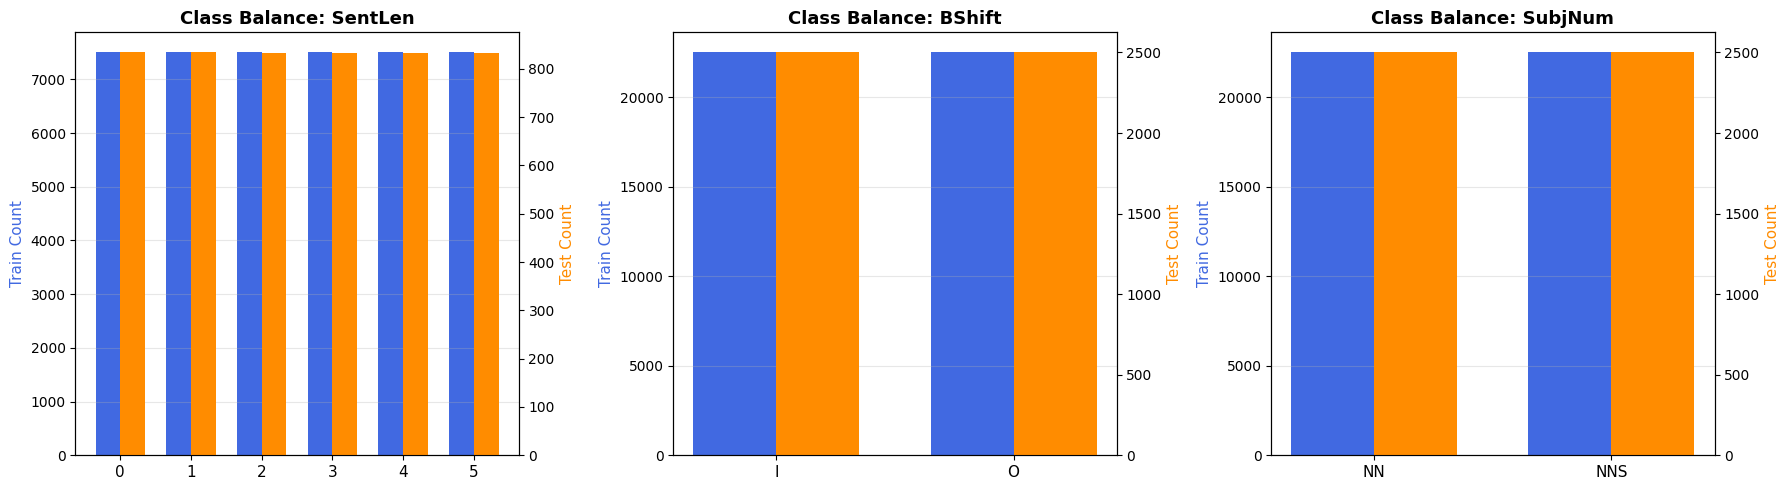

In [7]:
# Step 4.2: Visualize Class Balance across Splits
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
palette = sns.color_palette("muted")

for idx, (task_name, split_data) in enumerate(task_splits.items()):
    train_counts = np.bincount(split_data["y_train"])
    test_counts = np.bincount(split_data["y_test"])
    class_names = [str(c) for c in split_data["classes"]]
    
    x = np.arange(len(class_names))
    width = 0.35
    
    ax = axes[idx]
    ax.bar(x - width/2, train_counts, width, label='Train (90%)', color='royalblue')
    # Use twinx for test counts since train is 9x larger
    ax2 = ax.twinx()
    ax2.bar(x + width/2, test_counts, width, label='Test (10%)', color='darkorange')
    
    ax.set_title(f"Class Balance: {task_name}", fontsize=13, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(class_names, fontsize=11)
    ax.set_ylabel("Train Count", color='royalblue', fontsize=11)
    ax2.set_ylabel("Test Count", color='darkorange', fontsize=11)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()



---
## 5. BERT Layer-wise Sentence Representation Extraction

### 5.1 Architecture & Hidden States Extraction
In BERT (`bert-base-uncased`), an input sentence passes through:
1. **Embedding Layer ($L_0$):** WordPiece tokens + Positional + Segment embeddings.
2. **12 Bidirectional Transformer Encoder Layers ($L_1$ to $L_{12}$):** Each layer contains multi-head self-attention and feed-forward sublayers with residual connections ($d_{\text{model}} = 768$).

By setting `output_hidden_states=True` in HuggingFace `transformers`, the forward pass outputs a tuple of **13 hidden state tensors**:
$$\text{hidden\_states} = \big[h^{(0)}, h^{(1)}, h^{(2)}, \dots, h^{(12)}\big]$$
where each $h^{(l)} \in \mathbb{R}^{\text{batch\_size} \times \text{seq\_len} \times 768}$.

### 5.2 Sentence Pooling Strategy
To obtain a fixed-size vector representation of the sentence at layer $l$:
- **Mean Pooling (Default):** Average over all valid token representations ignoring padding tokens:
  $$u^{(l)} = \frac{\sum_{i=1}^{\text{seq\_len}} m_i \cdot h_i^{(l)}}{\sum_{i=1}^{\text{seq\_len}} m_i}$$
  where $m_i \in \{0, 1\}$ is the attention mask.
- **[CLS] Token:** The representation of the first token $h_0^{(l)}$. Mean pooling typically provides a more comprehensive representation across the entire sentence for surface and syntactic probing.


In [8]:
# Step 5.1: Initialize Pre-trained BERT Model and Tokenizer
print(f"Loading pre-trained tokenizer and model: '{MODEL_NAME}'...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
bert_model = AutoModel.from_pretrained(MODEL_NAME, output_hidden_states=True)
bert_model.eval()  # Freeze weights and disable dropout
bert_model.to(DEVICE)

total_params = sum(p.numel() for p in bert_model.parameters())
print(f"Loaded {MODEL_NAME} successfully.")
print(f"Total Parameters: {total_params / 1e6:.1f}M")
print(f"Number of Encoder Layers: {bert_model.config.num_hidden_layers}")
print(f"Hidden Dimension (d_model): {bert_model.config.hidden_size}")



Loading pre-trained tokenizer and model: 'bert-base-uncased'...


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loaded bert-base-uncased successfully.
Total Parameters: 109.5M
Number of Encoder Layers: 12
Hidden Dimension (d_model): 768


In [9]:
# Step 5.2: PyTorch Dataset & High-Throughput Layer Representation Extractor
class ProbingTextDataset(Dataset):
    # PyTorch Dataset for probing sentence strings
    def __init__(self, texts):
        self.texts = texts

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        return self.texts[idx]

def extract_layer_representations(texts, model, tokenizer, batch_size=128, max_length=64, pooling="mean", device=DEVICE):
    # Extracts sentence representations from all 12 BERT encoder layers.
    # Returns:
    #     layers_embeddings: dict mapping layer index (1 to 12) -> numpy array of shape (N, 768)
    dataset = ProbingTextDataset(texts)
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    
    # 12 layers: 1 to 12 (skipping 0 which is embedding layer)
    num_layers = model.config.num_hidden_layers  # 12
    layer_tensors = [[] for _ in range(num_layers)]
    
    model.eval()
    with torch.no_grad():
        for batch_texts in tqdm(dataloader, desc="Extracting BERT Layer Representations"):
            encoded = tokenizer(
                list(batch_texts),
                padding=True,
                truncation=True,
                max_length=max_length,
                return_tensors="pt"
            )
            input_ids = encoded["input_ids"].to(device)
            attention_mask = encoded["attention_mask"].to(device)
            
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            # outputs.hidden_states is a tuple of 13 tensors: (layer_0, layer_1, ..., layer_12)
            hidden_states = outputs.hidden_states
            
            mask_expanded = attention_mask.unsqueeze(-1).expand_as(hidden_states[0]).float()
            
            for layer_idx in range(1, num_layers + 1):
                h = hidden_states[layer_idx]  # shape: (B, L, 768)
                if pooling == "cls":
                    rep = h[:, 0, :]  # [CLS] token
                else:  # mean pooling
                    sum_h = torch.sum(h * mask_expanded, dim=1)
                    sum_mask = torch.clamp(mask_expanded.sum(dim=1), min=1e-9)
                    rep = sum_h / sum_mask
                
                layer_tensors[layer_idx - 1].append(rep.cpu().numpy().astype(np.float32))
    
    # Concatenate across batches
    layer_dict = {}
    for layer_idx in range(1, num_layers + 1):
        layer_dict[layer_idx] = np.concatenate(layer_tensors[layer_idx - 1], axis=0)
        
    return layer_dict



---
## 6. Training 12 Logistic Regression Probing Classifiers per Task

### 6.1 The Probing Methodology
The core hypothesis behind linear probing is:
$$\text{If a simple linear classifier (Logistic Regression) trained on representation } h^{(l)} \text{ achieves high accuracy on task } T,$$
$$\text{then linguistic property } T \text{ is explicitly and linearly accessible in layer } l.$$

For each task $T \in \{\text{SentLen}, \text{BShift}, \text{SubjNum}\}$:
- We iterate through all 12 encoder layers $l \in \{1, 2, \dots, 12\}$.
- Train a `LogisticRegression` model on $X_{\text{train}}^{(l)} \in \mathbb{R}^{45000 \times 768}$ with targets $y_{\text{train}}$.
- Evaluate on test set $X_{\text{test}}^{(l)} \in \mathbb{R}^{5000 \times 768}$ with targets $y_{\text{test}}$.
- Calculate:
  - **Accuracy**
  - **Macro-F1 Score**
  - **Macro-Precision & Macro-Recall**

Total models trained: $3 \text{ tasks} \times 12 \text{ layers} = \mathbf{36\text{ Logistic Regression Models}}$.


In [10]:
# Step 6.1: Define Probing Trainer & Evaluator
def train_and_evaluate_probing_models(
    X_train_layers, y_train,
    X_test_layers, y_test,
    task_name,
    num_layers=12,
    max_iter=1000
):
    # Trains and evaluates 12 Logistic Regression classifiers (one per BERT encoder layer).
    # Returns:
    #     results_df: DataFrame containing metrics for each layer
    #     trained_models: dict mapping layer index -> fitted model
    records = []
    trained_models = {}
    
    print(f"\n=======================================================")
    print(f" Training 12 Probing Models for Task: {task_name}")
    print(f"=======================================================")
    
    for layer in range(1, num_layers + 1):
        X_tr = X_train_layers[layer]
        X_te = X_test_layers[layer]
        
        t0 = time.time()
        # Pipeline with StandardScaler and LogisticRegression
        # Using L-BFGS solver with multiclass/cross-entropy support
        clf = Pipeline([
            ('scaler', StandardScaler()),
            ('lr', LogisticRegression(
                max_iter=max_iter,
                solver='lbfgs',
                random_state=SEED,
                n_jobs=-1
            ))
        ])
        
        clf.fit(X_tr, y_train)
        train_time = time.time() - t0
        
        # Predictions
        y_pred = clf.predict(X_te)
        
        # Metrics
        acc = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)
        prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
        rec = recall_score(y_test, y_pred, average='macro', zero_division=0)
        
        trained_models[layer] = clf
        records.append({
            "Task": task_name,
            "Layer": layer,
            "Test Accuracy": acc,
            "Macro F1": f1,
            "Macro Precision": prec,
            "Macro Recall": rec,
            "Train Time (s)": round(train_time, 2)
        })
        
        print(f"Layer {layer:02d} | Test Acc: {acc*100:6.2f}% | Macro F1: {f1*100:6.2f}% | Time: {train_time:5.1f}s")
        
    results_df = pd.DataFrame(records)
    return results_df, trained_models



---
## 7. Model Execution & Evaluation

We now run the complete pipeline across all three tasks sequentially:
1. **Task 1: Sentence Length (`SentLen`)**
2. **Task 2: Bigram Shift (`BShift`)**
3. **Task 3: Subject Number (`SubjNum`)**


In [11]:
# Step 7.1: Task 1 - Sentence Length (SentLen)
task1_name = "SentLen"
split1 = task_splits[task1_name]

print(f"\n>>> Extracting BERT features for {task1_name} (Train: {len(split1['train_texts'])}, Test: {len(split1['test_texts'])})")
X_train_layers_1 = extract_layer_representations(split1["train_texts"], bert_model, tokenizer, batch_size=BATCH_SIZE, max_length=MAX_LENGTH, pooling=POOLING_STRATEGY)
X_test_layers_1 = extract_layer_representations(split1["test_texts"], bert_model, tokenizer, batch_size=BATCH_SIZE, max_length=MAX_LENGTH, pooling=POOLING_STRATEGY)

results_task1, models_task1 = train_and_evaluate_probing_models(
    X_train_layers_1, split1["y_train"],
    X_test_layers_1, split1["y_test"],
    task_name=task1_name
)




>>> Extracting BERT features for SentLen (Train: 45000, Test: 5000)


Extracting BERT Layer Representations:   0%|          | 0/352 [00:00<?, ?it/s]

Extracting BERT Layer Representations:   0%|          | 0/40 [00:00<?, ?it/s]


 Training 12 Probing Models for Task: SentLen
Layer 01 | Test Acc:  96.32% | Macro F1:  96.32% | Time:  24.8s
Layer 02 | Test Acc:  95.84% | Macro F1:  95.83% | Time:  25.7s
Layer 03 | Test Acc:  95.58% | Macro F1:  95.58% | Time:  27.1s
Layer 04 | Test Acc:  94.72% | Macro F1:  94.71% | Time:  36.9s
Layer 05 | Test Acc:  93.66% | Macro F1:  93.65% | Time:  34.5s
Layer 06 | Test Acc:  93.20% | Macro F1:  93.19% | Time:  38.5s
Layer 07 | Test Acc:  92.04% | Macro F1:  92.03% | Time:  34.6s
Layer 08 | Test Acc:  91.02% | Macro F1:  91.01% | Time:  36.2s
Layer 09 | Test Acc:  88.86% | Macro F1:  88.84% | Time:  37.7s
Layer 10 | Test Acc:  87.16% | Macro F1:  87.16% | Time:  40.0s
Layer 11 | Test Acc:  85.86% | Macro F1:  85.84% | Time:  37.9s
Layer 12 | Test Acc:  83.20% | Macro F1:  83.20% | Time:  32.8s


In [12]:
# Step 7.2: Task 2 - Bigram Shift (BShift)
task2_name = "BShift"
split2 = task_splits[task2_name]

print(f"\n>>> Extracting BERT features for {task2_name} (Train: {len(split2['train_texts'])}, Test: {len(split2['test_texts'])})")
X_train_layers_2 = extract_layer_representations(split2["train_texts"], bert_model, tokenizer, batch_size=BATCH_SIZE, max_length=MAX_LENGTH, pooling=POOLING_STRATEGY)
X_test_layers_2 = extract_layer_representations(split2["test_texts"], bert_model, tokenizer, batch_size=BATCH_SIZE, max_length=MAX_LENGTH, pooling=POOLING_STRATEGY)

results_task2, models_task2 = train_and_evaluate_probing_models(
    X_train_layers_2, split2["y_train"],
    X_test_layers_2, split2["y_test"],
    task_name=task2_name
)




>>> Extracting BERT features for BShift (Train: 45000, Test: 5000)


Extracting BERT Layer Representations:   0%|          | 0/352 [00:00<?, ?it/s]

Extracting BERT Layer Representations:   0%|          | 0/40 [00:00<?, ?it/s]


 Training 12 Probing Models for Task: BShift
Layer 01 | Test Acc:  57.96% | Macro F1:  57.96% | Time:   7.7s
Layer 02 | Test Acc:  71.16% | Macro F1:  71.15% | Time:   6.6s
Layer 03 | Test Acc:  82.92% | Macro F1:  82.92% | Time:   6.9s
Layer 04 | Test Acc:  86.14% | Macro F1:  86.14% | Time:   5.1s
Layer 05 | Test Acc:  87.42% | Macro F1:  87.42% | Time:   3.8s
Layer 06 | Test Acc:  88.90% | Macro F1:  88.90% | Time:   4.1s
Layer 07 | Test Acc:  89.82% | Macro F1:  89.82% | Time:   4.2s
Layer 08 | Test Acc:  90.76% | Macro F1:  90.76% | Time:   4.6s
Layer 09 | Test Acc:  90.26% | Macro F1:  90.25% | Time:   5.1s
Layer 10 | Test Acc:  89.68% | Macro F1:  89.68% | Time:   5.4s
Layer 11 | Test Acc:  89.44% | Macro F1:  89.43% | Time:   5.2s
Layer 12 | Test Acc:  88.26% | Macro F1:  88.25% | Time:   5.5s


In [13]:
# Step 7.3: Task 3 - Subject Number (SubjNum)
task3_name = "SubjNum"
split3 = task_splits[task3_name]

print(f"\n>>> Extracting BERT features for {task3_name} (Train: {len(split3['train_texts'])}, Test: {len(split3['test_texts'])})")
X_train_layers_3 = extract_layer_representations(split3["train_texts"], bert_model, tokenizer, batch_size=BATCH_SIZE, max_length=MAX_LENGTH, pooling=POOLING_STRATEGY)
X_test_layers_3 = extract_layer_representations(split3["test_texts"], bert_model, tokenizer, batch_size=BATCH_SIZE, max_length=MAX_LENGTH, pooling=POOLING_STRATEGY)

results_task3, models_task3 = train_and_evaluate_probing_models(
    X_train_layers_3, split3["y_train"],
    X_test_layers_3, split3["y_test"],
    task_name=task3_name
)




>>> Extracting BERT features for SubjNum (Train: 45000, Test: 5000)


Extracting BERT Layer Representations:   0%|          | 0/352 [00:00<?, ?it/s]

Extracting BERT Layer Representations:   0%|          | 0/40 [00:00<?, ?it/s]


 Training 12 Probing Models for Task: SubjNum
Layer 01 | Test Acc:  84.72% | Macro F1:  84.72% | Time:   5.4s
Layer 02 | Test Acc:  85.00% | Macro F1:  85.00% | Time:   5.1s
Layer 03 | Test Acc:  85.98% | Macro F1:  85.98% | Time:   5.0s
Layer 04 | Test Acc:  87.16% | Macro F1:  87.16% | Time:   6.3s
Layer 05 | Test Acc:  88.76% | Macro F1:  88.76% | Time:   7.3s
Layer 06 | Test Acc:  88.88% | Macro F1:  88.88% | Time:   6.6s
Layer 07 | Test Acc:  89.46% | Macro F1:  89.46% | Time:   6.2s
Layer 08 | Test Acc:  88.62% | Macro F1:  88.62% | Time:   5.5s
Layer 09 | Test Acc:  88.28% | Macro F1:  88.28% | Time:   3.8s
Layer 10 | Test Acc:  88.02% | Macro F1:  88.02% | Time:   4.2s
Layer 11 | Test Acc:  86.78% | Macro F1:  86.78% | Time:   3.6s
Layer 12 | Test Acc:  86.74% | Macro F1:  86.74% | Time:   3.9s


---
## 8. Comparative Analysis & Visualizations

We consolidate the test results across all 36 models into a master comparison table and plot the layer-wise performance trajectories.


In [14]:
# Step 8.1: Master Comparison Table across all 36 Models
all_results_df = pd.concat([results_task1, results_task2, results_task3], ignore_index=True)

# Format for clean display
styled_table = all_results_df.pivot(index="Layer", columns="Task", values="Test Accuracy")
styled_table_pct = styled_table * 100

print("=" * 70)
print(" BERT 12-LAYER PROBING ACCURACY (%) COMPARISON TABLE")
print("=" * 70)
print(styled_table_pct.round(2).to_string())

# Display comprehensive summary table
styled_summary = all_results_df.pivot(index="Layer", columns="Task", values=["Test Accuracy", "Macro F1"])
print("\n" + "=" * 70)
print(" ACCURACY & MACRO-F1 SUMMARY")
print("=" * 70)
print((styled_summary * 100).round(2).to_string())



 BERT 12-LAYER PROBING ACCURACY (%) COMPARISON TABLE
Task   BShift  SentLen  SubjNum
Layer                          
1       57.96    96.32    84.72
2       71.16    95.84    85.00
3       82.92    95.58    85.98
4       86.14    94.72    87.16
5       87.42    93.66    88.76
6       88.90    93.20    88.88
7       89.82    92.04    89.46
8       90.76    91.02    88.62
9       90.26    88.86    88.28
10      89.68    87.16    88.02
11      89.44    85.86    86.78
12      88.26    83.20    86.74

 ACCURACY & MACRO-F1 SUMMARY
      Test Accuracy                 Macro F1                
Task         BShift SentLen SubjNum   BShift SentLen SubjNum
Layer                                                       
1             57.96   96.32   84.72    57.96   96.32   84.72
2             71.16   95.84   85.00    71.15   95.83   85.00
3             82.92   95.58   85.98    82.92   95.58   85.98
4             86.14   94.72   87.16    86.14   94.71   87.16
5             87.42   93.66   88.76    87.

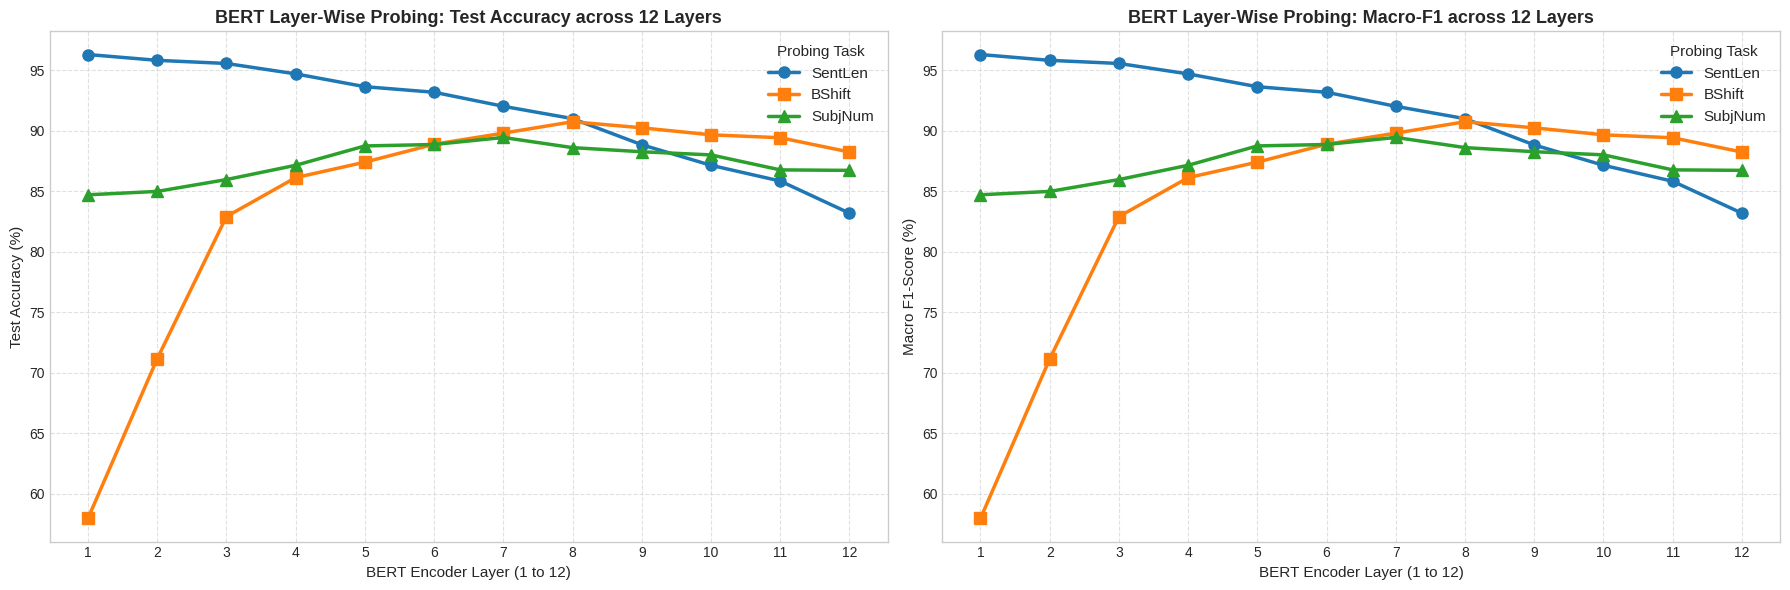

In [15]:
# Step 8.2: Layer-wise Accuracy Comparison Plot (Line Chart)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

markers = {'SentLen': 'o', 'BShift': 's', 'SubjNum': '^'}
colors = {'SentLen': '#1f77b4', 'BShift': '#ff7f0e', 'SubjNum': '#2ca02c'}

# Plot 1: Test Accuracy vs Layer
for task in ['SentLen', 'BShift', 'SubjNum']:
    sub = all_results_df[all_results_df['Task'] == task]
    ax1.plot(
        sub['Layer'], sub['Test Accuracy'] * 100,
        marker=markers[task], color=colors[task],
        linewidth=2.5, markersize=8, label=f"{task}"
    )

ax1.set_title("BERT Layer-Wise Probing: Test Accuracy across 12 Layers", fontsize=13, fontweight='bold')
ax1.set_xlabel("BERT Encoder Layer (1 to 12)", fontsize=11)
ax1.set_ylabel("Test Accuracy (%)", fontsize=11)
ax1.set_xticks(range(1, 13))
ax1.legend(title="Probing Task", fontsize=11, title_fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.6)

# Plot 2: Macro F1 vs Layer
for task in ['SentLen', 'BShift', 'SubjNum']:
    sub = all_results_df[all_results_df['Task'] == task]
    ax2.plot(
        sub['Layer'], sub['Macro F1'] * 100,
        marker=markers[task], color=colors[task],
        linewidth=2.5, markersize=8, label=f"{task}"
    )

ax2.set_title("BERT Layer-Wise Probing: Macro-F1 across 12 Layers", fontsize=13, fontweight='bold')
ax2.set_xlabel("BERT Encoder Layer (1 to 12)", fontsize=11)
ax2.set_ylabel("Macro F1-Score (%)", fontsize=11)
ax2.set_xticks(range(1, 13))
ax2.legend(title="Probing Task", fontsize=11, title_fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()



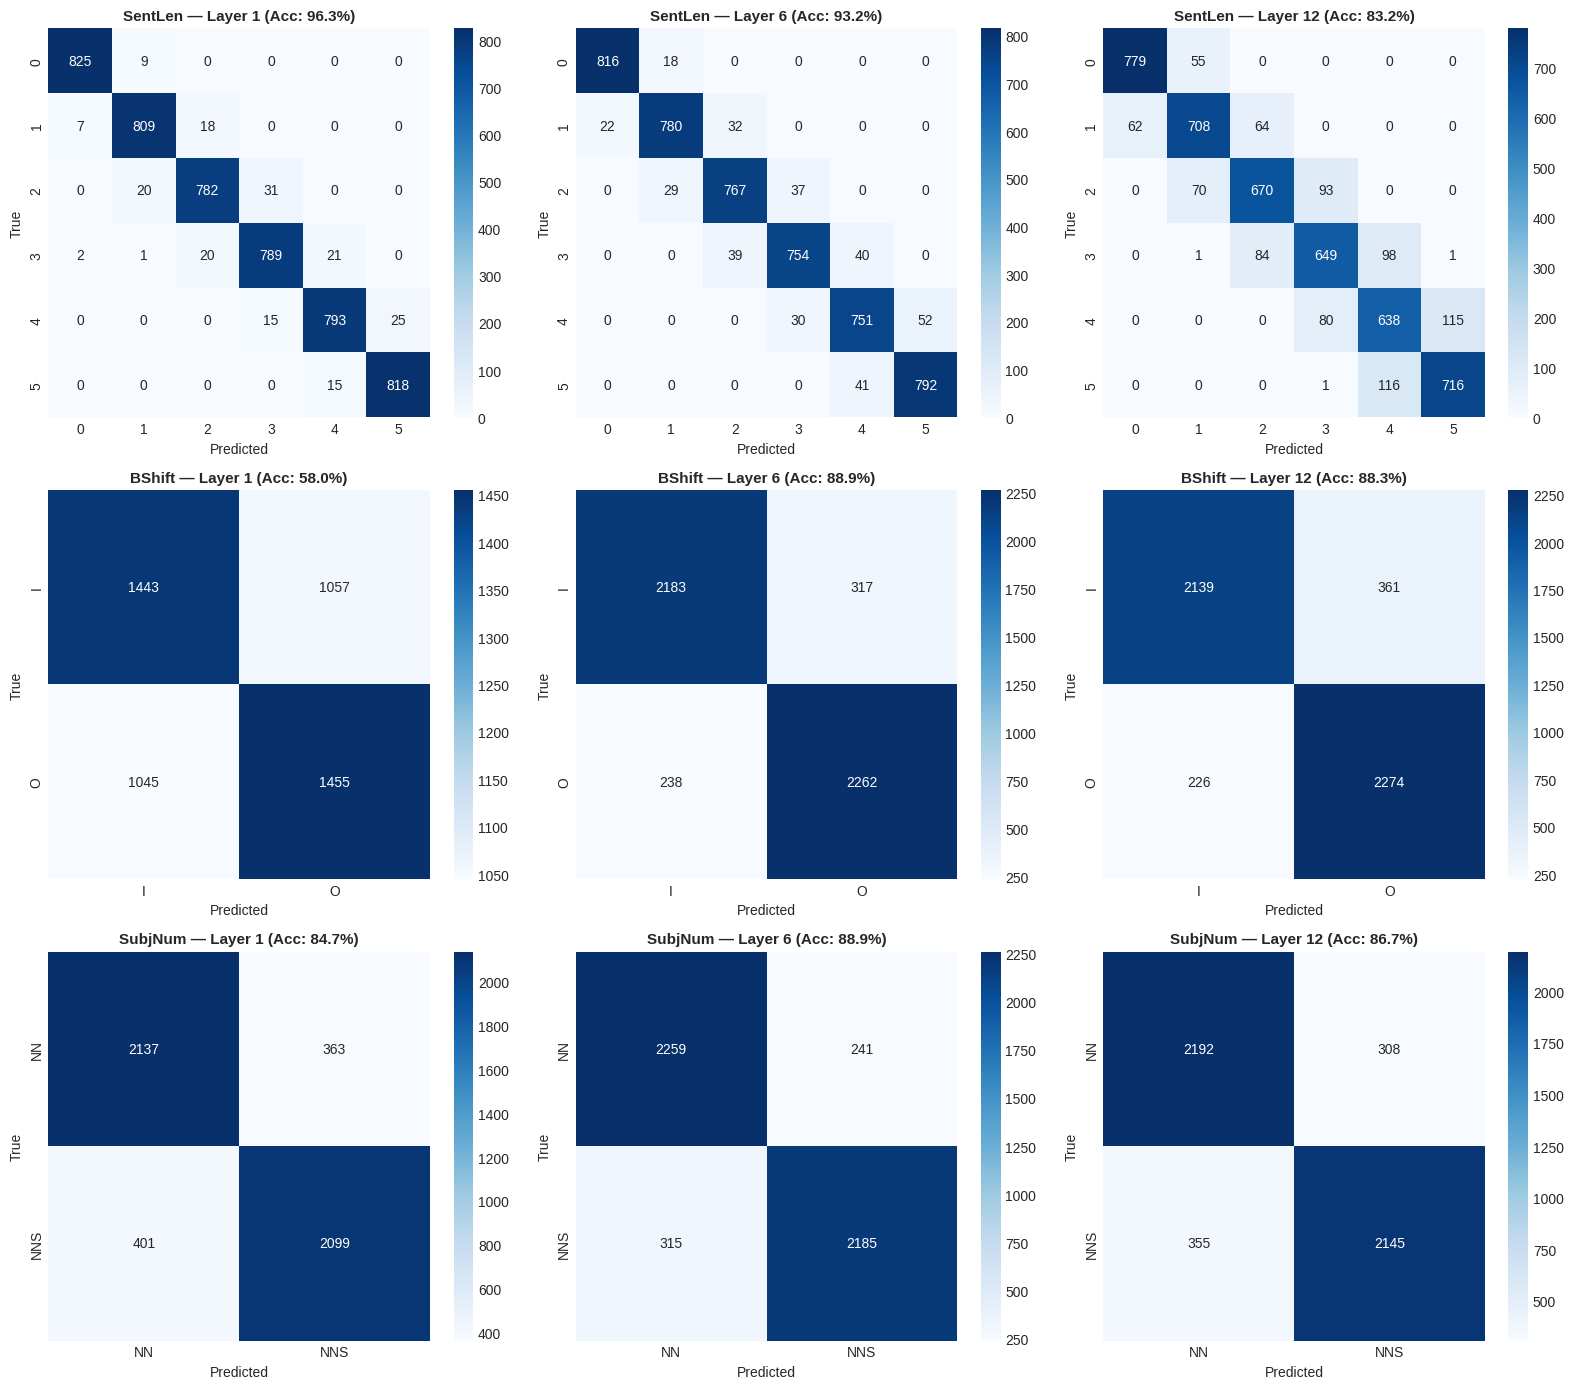

In [16]:
# Step 8.3: Confusion Matrix Analysis across Representative Layers (Early vs Mid vs Late)
key_layers = [1, 6, 12]
fig, axes = plt.subplots(3, 3, figsize=(16, 14))

task_tuples = [
    ("SentLen", split1, models_task1, X_test_layers_1),
    ("BShift", split2, models_task2, X_test_layers_2),
    ("SubjNum", split3, models_task3, X_test_layers_3)
]

for row_idx, (t_name, s_data, t_models, X_te_layers) in enumerate(task_tuples):
    class_labels = [str(c) for c in s_data["classes"]]
    for col_idx, layer in enumerate(key_layers):
        clf = t_models[layer]
        y_pred = clf.predict(X_te_layers[layer])
        cm = confusion_matrix(s_data["y_test"], y_pred)
        
        ax = axes[row_idx, col_idx]
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                    xticklabels=class_labels, yticklabels=class_labels)
        ax.set_title(f"{t_name} — Layer {layer} (Acc: {accuracy_score(s_data['y_test'], y_pred)*100:.1f}%)",
                     fontsize=11, fontweight='bold')
        ax.set_xlabel("Predicted")
        ax.set_ylabel("True")

plt.tight_layout()
plt.show()

